# Model Training, Evaluation and Selection

**Author:** Abdullah Irshad CT-24271

This notebook compares classification models for the SDSS stellar-object dataset. The target is `class` (`GALAXY`, `STAR`, or `QSO`). The aim is to find a model that maintains good classification performance while using fewer input features. All model selection and experiments use the training set; the test set is reserved for the final evaluation.

## 1. Define the problem

This is a **multi-class classification** problem. Each row represents an astronomical observation, and the model predicts whether the object is a galaxy, star, or quasar.

The input columns contain six original measurements (`u`, `g`, `r`, `i`, `z`, `redshift`) and four derived colour indices (`u_g`, `g_r`, `r_i`, `i_z`).

**Important distinction:** reducing columns is not necessarily the same as reducing original telescope measurements. A colour index such as `u_g` is calculated from `u` and `g`; it is not an independent measurement. A separate experiment below compares original measurements with derived features.

## 2. Load the prepared train and test sets

Load `stellar_train_raw.csv` and `stellar_test_raw.csv` created in Phase 1. Both files must contain the same numeric feature columns and the target column `class`. Missing feature values are allowed because imputation is handled inside the model pipeline.

**Why use a pipeline?** Imputation, feature selection and scaling learn information from data. If fitted before cross-validation, validation folds can influence those transformations. Keeping them inside the pipeline makes scikit-learn fit them separately using only each fold's training portion.

In [ ]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

%load_ext cuml.accel

from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
TARGET = "class"

train = pd.read_csv("stellar_train_raw.csv")
test = pd.read_csv("stellar_test_raw.csv")

assert TARGET in train.columns and TARGET in test.columns, "Missing target column 'class'."
FEATURE_COLUMNS = [col for col in train.columns if col != TARGET]
X_train, y_train = train[FEATURE_COLUMNS].copy(), train[TARGET].copy()
X_test, y_test = test[FEATURE_COLUMNS].copy(), test[TARGET].copy()
assert list(X_train.columns) == list(X_test.columns), "Train/test feature columns differ."
assert set(y_train.unique()) == set(y_test.unique()), "Train/test class labels differ."
assert X_train.select_dtypes(include=np.number).shape[1] == len(FEATURE_COLUMNS), "Features must be numeric."

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Features:", FEATURE_COLUMNS)
print("Classes:", sorted(y_train.unique()))
print("\nMissing values in training features:")
display(X_train.isna().sum().to_frame("Missing count"))
print("Training class distribution:")
display(y_train.value_counts().rename("Count").to_frame())

Training set: (80000, 10)
Testing set: (20000, 10)
Features: ['u', 'g', 'r', 'i', 'z', 'redshift', 'u_g', 'g_r', 'r_i', 'i_z']
Classes: ['GALAXY', 'QSO', 'STAR']

Missing values in training features:


,Missing count
u,1
g,1
r,0
i,0
z,1
redshift,0
u_g,1
g_r,1
r_i,0
i_z,1


Training class distribution:


,Count
class,
GALAXY,47556
STAR,17275
QSO,15169


## 3. Train and compare multiple models

We use **5-fold stratified cross-validation**, so each fold keeps approximately the same class proportions. Macro F1-score is the main comparison metric because it gives each class equal weight rather than letting the largest class dominate.

**Scaling decision:** Logistic Regression, Linear SVM and KNN are sensitive to feature magnitudes, so they use `StandardScaler`. Tree-based models split on feature values and generally do not need standardisation. The imputer and feature selector remain inside every pipeline so they are fitted separately within each fold.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision_macro": "precision_macro",
           "recall_macro": "recall_macro", "f1_macro": "f1_macro"}

def create_pipeline(model, scale=True, k="all"):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("scaler", StandardScaler() if scale else "passthrough"),
        ("model", model)
    ])

### Models to compare

These models cover linear, distance-based, probabilistic, tree-based and ensemble approaches. The initial settings are starting points, not claimed to be optimal; the selected model is tuned later.

In [ ]:
models = {
    "Logistic Regression": {"model": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE), "scale": True},
    "Linear SVM": {"model": LinearSVC(C=1.0, dual=False, random_state=RANDOM_STATE), "scale": True},
    "K-Nearest Neighbors": {"model": KNeighborsClassifier(n_neighbors=5, n_jobs=1), "scale": True},
    "Gaussian Naive Bayes": {"model": GaussianNB(), "scale": False},
    "Decision Tree": {"model": DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=2), "scale": False},
    "Extra Trees": {"model": ExtraTreesClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1, class_weight="balanced"), "scale": False},
    "HistGradientBoosting": {"model": HistGradientBoostingClassifier(random_state=RANDOM_STATE, learning_rate=0.05, max_iter=100, max_leaf_nodes=31), "scale": False},
    "Random Forest": {"model": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1, class_weight="balanced"), "scale": False}
}

model_results = []
for name, config in models.items():
    pipeline = create_pipeline(config["model"], config["scale"])
    start = time.perf_counter()
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    elapsed = time.perf_counter() - start
    model_results.append({
        "Model": name, "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision_macro"].mean(),
        "Recall": scores["test_recall_macro"].mean(),
        "F1-score": scores["test_f1_macro"].mean(),
        "Fit time (s/fold)": scores["fit_time"].mean(),
        "Score time (s/fold)": scores["score_time"].mean(),
        "Total CV time (s)": elapsed
    })
    print(f"{name}: completed in {elapsed:.2f} seconds")

comparison_df = pd.DataFrame(model_results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

Logistic Regression: completed in 5.24 seconds
[2026-11-16 17:48:39.133] [CUML] [warning] L-BFGS stopped, because the line search failed to advance (step delta = 0.000000)
Linear SVM: completed in 2.26 seconds
K-Nearest Neighbors: completed in 2.41 seconds
Gaussian Naive Bayes: completed in 2.76 seconds
Decision Tree: completed in 11.54 seconds
Extra Trees: completed in 41.46 seconds
HistGradientBoosting: completed in 17.27 seconds
Random Forest: completed in 180.64 seconds


,Model,Accuracy,Precision,Recall,F1-score,Fit time (s/fold),Score time (s/fold),Total CV time (s)
0,Random Forest,0.9790,0.9790,0.9724,0.9756,35.6694,0.4284,180.6402
1,HistGradientBoosting,0.9771,0.9766,0.9705,0.9735,2.8304,0.6084,17.2744
2,Extra Trees,0.9744,0.9734,0.9680,0.9705,7.5397,0.7357,41.4567
3,Decision Tree,0.9680,0.9654,0.9602,0.9628,2.1042,0.1772,11.5432
4,K-Nearest Neighbors,0.9557,0.9525,0.9489,0.9504,0.1786,0.2871,2.4083
5,Logistic Regression,0.9550,0.9507,0.9469,0.9482,0.7643,0.2564,5.2449
6,Linear SVM,0.9357,0.9311,0.9257,0.9282,0.2344,0.2016,2.2585
7,Gaussian Naive Bayes,0.9272,0.9069,0.9376,0.9198,0.2927,0.2429,2.7561


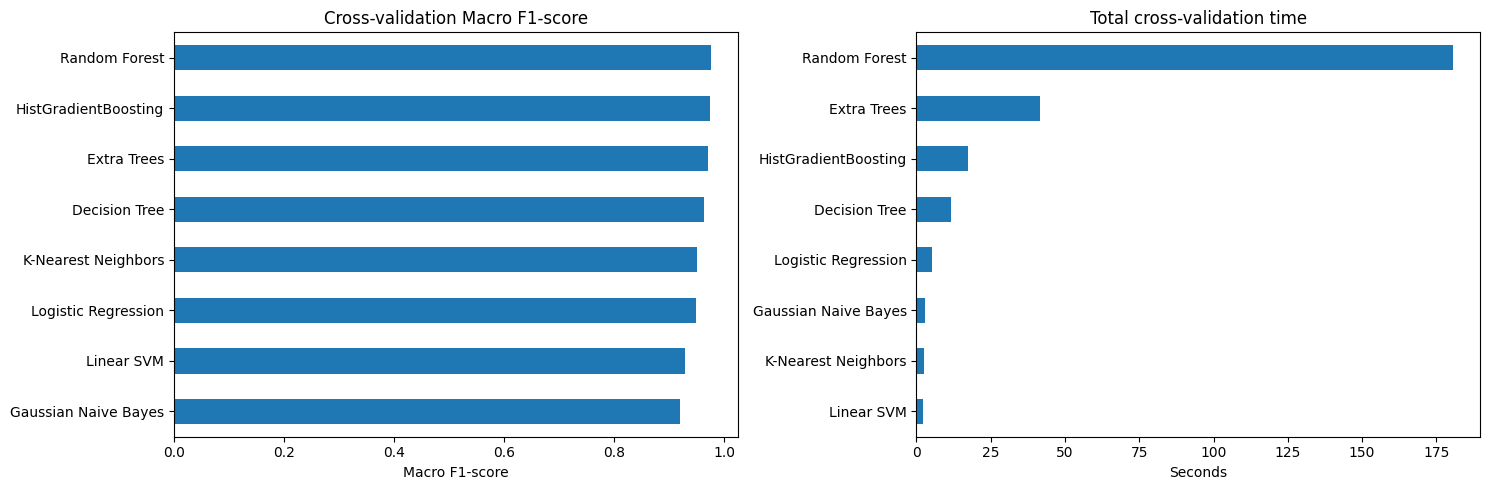

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comparison_df.sort_values("F1-score").plot(x="Model", y="F1-score", kind="barh", ax=axes[0], legend=False)
axes[0].set_title("Cross-validation Macro F1-score")
axes[0].set_xlabel("Macro F1-score")
axes[0].set_ylabel("")
comparison_df.sort_values("Total CV time (s)").plot(x="Model", y="Total CV time (s)", kind="barh", ax=axes[1], legend=False)
axes[1].set_title("Total cross-validation time")
axes[1].set_xlabel("Seconds")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

### Select a model

The rule selects the **fastest model within 0.005 macro F1-score of the best score**. This is a practical speed/performance trade-off, not a universal statistical rule. The table shows which models qualify.

In [ ]:
best_cv_f1 = comparison_df["F1-score"].max()
acceptable_models = comparison_df[comparison_df["F1-score"] >= best_cv_f1 - 0.005].copy()
selected_model_name = acceptable_models.sort_values("Total CV time (s)").iloc[0]["Model"]
worst_model_name = comparison_df.iloc[-1]["Model"]
print("Highest CV F1-score:", round(best_cv_f1, 4))
print("Selected model:", selected_model_name)
print("Lowest-scoring model:", worst_model_name)
display(acceptable_models[["Model", "F1-score", "Total CV time (s)"]].round(4))

Highest CV F1-score: 0.9756
Selected model: HistGradientBoosting
Lowest-scoring model: Gaussian Naive Bayes


,Model,F1-score,Total CV time (s)
0,Random Forest,0.9756,180.6402
1,HistGradientBoosting,0.9735,17.2744


### Compare against a simple baseline

A `DummyClassifier` predicts the most frequent class without learning relationships between features and target. A useful model should perform substantially better than this reference.

In [ ]:
dummy_pipeline = create_pipeline(DummyClassifier(strategy="most_frequent"), scale=False)
dummy_scores = cross_validate(dummy_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
dummy_f1 = dummy_scores["test_f1_macro"].mean()
dummy_row = pd.DataFrame([{
    "Model": "Dummy Classifier", "Accuracy": dummy_scores["test_accuracy"].mean(),
    "Precision": dummy_scores["test_precision_macro"].mean(),
    "Recall": dummy_scores["test_recall_macro"].mean(), "F1-score": dummy_f1
}])
display(dummy_row.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

,Model,Accuracy,Precision,Recall,F1-score
0,Dummy Classifier,0.5944,0.1982,0.3333,0.2485


## 4. Hyperparameter tuning

Only the selected model is tuned to keep runtime manageable. `GridSearchCV` tests the listed parameter combinations using the same stratified folds and chooses the highest mean macro F1-score. The grid is deliberately modest; larger searches can take much longer on this dataset.

Selected model: HistGradientBoosting
Best parameters: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.1, 'model__max_iter': 80, 'model__max_leaf_nodes': 63}
Best CV Macro F1: 0.9737
Tuning time: 230.63 seconds


,Version,CV Macro F1-score
0,Before tuning,0.9735
1,After tuning,0.9737


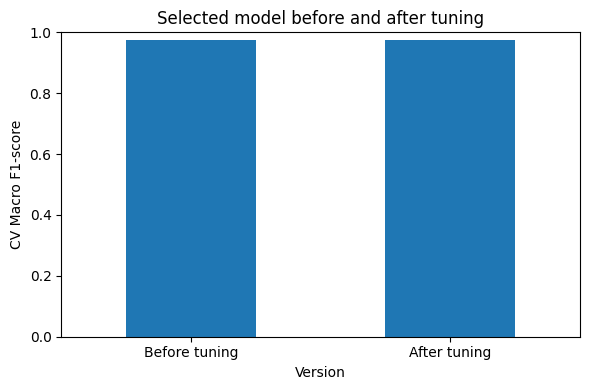

In [ ]:
param_grids = {
    "HistGradientBoosting": {"model__learning_rate": [0.05, 0.1], "model__max_iter": [80, 120], "model__max_leaf_nodes": [31, 63], "model__l2_regularization": [0.0, 0.1]},
    "Extra Trees": {"model__n_estimators": [100, 150], "model__max_features": ["sqrt", 0.8], "model__min_samples_leaf": [1, 2]},
    "Random Forest": {"model__n_estimators": [80, 120], "model__max_features": ["sqrt", 0.8], "model__min_samples_leaf": [1, 2]},
    "Logistic Regression": {"model__C": [0.1, 1.0, 3.0]},
    "Linear SVM": {"model__C": [0.1, 1.0, 3.0]},
    "K-Nearest Neighbors": {"model__n_neighbors": [3, 5, 7, 9], "model__weights": ["uniform", "distance"]},
    "Decision Tree": {"model__max_depth": [None, 10, 20], "model__min_samples_leaf": [1, 2, 4]},
    "Gaussian Naive Bayes": {"model__var_smoothing": [1e-9, 1e-8, 1e-7]}
}

selected_model = models[selected_model_name]
full_pipeline = create_pipeline(selected_model["model"], selected_model["scale"])
full_grid = GridSearchCV(full_pipeline, param_grids[selected_model_name], scoring="f1_macro", cv=cv, n_jobs=1)
tuning_start = time.perf_counter()
full_grid.fit(X_train, y_train)
tuning_time = time.perf_counter() - tuning_start
tuned_model = full_grid.best_estimator_

# Above variables are used for the before/after comparison.
baseline_cv_f1 = comparison_df.loc[comparison_df["Model"] == selected_model_name, "F1-score"].iloc[0]
tuning_comparison = pd.DataFrame({
    "Version": ["Before tuning", "After tuning"],
    "CV Macro F1-score": [baseline_cv_f1, full_grid.best_score_]
})
print("Selected model:", selected_model_name)
print("Best parameters:", full_grid.best_params_)
print("Best CV Macro F1:", round(full_grid.best_score_, 4))
print(f"Tuning time: {tuning_time:.2f} seconds")
display(tuning_comparison.round(4))
tuning_comparison.plot(x="Version", y="CV Macro F1-score", kind="bar", legend=False, figsize=(6, 4), ylim=(0, 1))
plt.title("Selected model before and after tuning")
plt.ylabel("CV Macro F1-score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Feature reduction experiment

`SelectKBest` with `f_classif` ranks each feature separately using an ANOVA F-test. It is a simple, reproducible starting method. The selector is inside the pipeline so its ranking is recalculated using only the training portion of each fold.

**Limitation:** univariate F-scores may miss features that are useful through interactions. Mutual information, recursive feature elimination, sequential selection, model-based selection or permutation importance are possible alternatives.

Each feature count is tuned independently. This avoids assuming that the best hyperparameters with all features will also be best with fewer features.

In [ ]:
feature_counts = sorted(set([2, 4, 6, 8, len(FEATURE_COLUMNS)]))
feature_results = []
feature_searches = {}
for k in feature_counts:
    feature_pipeline = create_pipeline(selected_model["model"], selected_model["scale"], k=k)
    grid = GridSearchCV(feature_pipeline, param_grids[selected_model_name], scoring="f1_macro", cv=cv, n_jobs=1)
    start = time.perf_counter()
    grid.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    feature_searches[k] = grid
    feature_results.append({"Number of features": k, "F1-score": grid.best_score_,
                            "Best parameters": grid.best_params_, "Total CV time (s)": elapsed})
    print(f"{k} features: CV F1 = {grid.best_score_:.4f}, time = {elapsed:.2f}s")
feature_results_df = pd.DataFrame(feature_results)
display(feature_results_df.round(4))

2 features: CV F1 = 0.9576, time = 165.51s
4 features: CV F1 = 0.9704, time = 186.49s
6 features: CV F1 = 0.9732, time = 203.60s
8 features: CV F1 = 0.9735, time = 216.70s
10 features: CV F1 = 0.9737, time = 228.19s


,Number of features,F1-score,Best parameters,Total CV time (s)
0,2,0.9576,"{'model__l2_regularization': 0.0, 'model__lear...",165.5094
1,4,0.9704,"{'model__l2_regularization': 0.0, 'model__lear...",186.4858
2,6,0.9732,"{'model__l2_regularization': 0.1, 'model__lear...",203.5995
3,8,0.9735,"{'model__l2_regularization': 0.1, 'model__lear...",216.7014
4,10,0.9737,"{'model__l2_regularization': 0.0, 'model__lear...",228.1874


In [ ]:
best_feature_f1 = feature_results_df["F1-score"].max()
feature_tolerance = 0.002
eligible_feature_counts = feature_results_df[feature_results_df["F1-score"] >= best_feature_f1 - feature_tolerance]
selected_k = int(eligible_feature_counts["Number of features"].min())
print("Best feature-count CV F1:", round(best_feature_f1, 4))
print("Allowed difference:", feature_tolerance)
print("Selected feature count:", selected_k)

Best feature-count CV F1: 0.9737
Allowed difference: 0.002
Selected feature count: 6


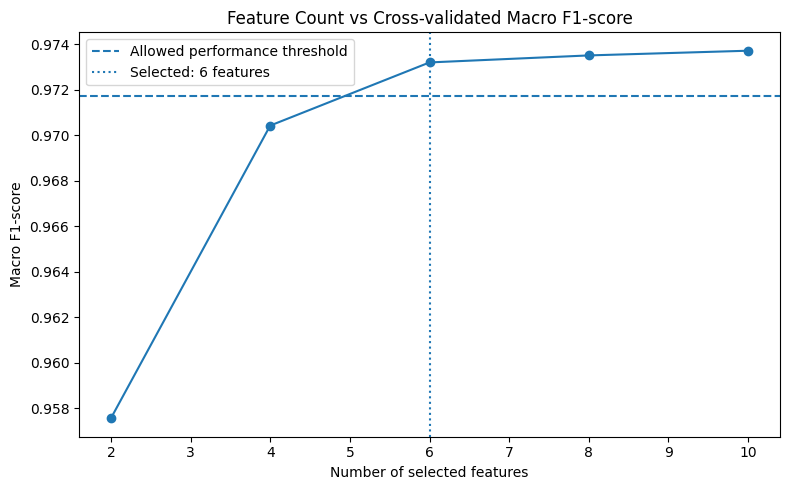

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(feature_results_df["Number of features"], feature_results_df["F1-score"], marker="o")
ax.axhline(best_feature_f1 - feature_tolerance, linestyle="--", label="Allowed performance threshold")
ax.axvline(selected_k, linestyle=":", label=f"Selected: {selected_k} features")
ax.set_title("Feature Count vs Cross-validated Macro F1-score")
ax.set_xlabel("Number of selected features")
ax.set_ylabel("Macro F1-score")
ax.legend()
plt.tight_layout()
plt.show()

### Inspect the selected features

`GridSearchCV` refits the best pipeline on the complete training set after selecting its parameters. We can inspect the fitted selector to see which columns were retained. The test set is not used to choose these columns.

In [ ]:
final_pipeline = feature_searches[selected_k].best_estimator_
selector = final_pipeline.named_steps["selector"]
selected_features = list(X_train.columns[selector.get_support()])
print("Selected features:", selected_features)
print("Number of selected features:", len(selected_features))
print("Number of removed columns:", len(FEATURE_COLUMNS) - len(selected_features))

Selected features: ['i', 'z', 'redshift', 'u_g', 'g_r', 'r_i']
Number of selected features: 6
Number of removed columns: 4


## 6. Compare original measurements and derived features

This experiment is different from selecting `k` columns:

- **Six original measurements:** five photometric bands and redshift.
- **Five photometric bands:** the five bands without redshift; this tests whether redshift contributes useful information.
- **Four colour indices:** only the derived colour columns.
- **All ten model columns:** the six original measurements plus four colour indices.

Each experiment is tuned and cross-validated using training data only. **Interpretation caution:** colour indices are calculated from original photometric bands. Using only colour-index columns reduces the model's input columns, but those values still depend on the original measurements. This does not prove that fewer telescope observations can be taken.

In [ ]:
RAW_FEATURES = ["u", "g", "r", "i", "z", "redshift"]
PHOTOMETRIC_FEATURES = ["u", "g", "r", "i", "z"]
COLOUR_FEATURES = ["u_g", "g_r", "r_i", "i_z"]
ALL_FEATURES = RAW_FEATURES + COLOUR_FEATURES
measurement_experiments = {
    "Six original measurements": RAW_FEATURES,
    "Five photometric bands (no redshift)": PHOTOMETRIC_FEATURES,
    "Four derived colour indices": COLOUR_FEATURES,
    "All ten model columns": ALL_FEATURES
}
for columns in measurement_experiments.values():
    missing = [col for col in columns if col not in X_train.columns]
    assert not missing, f"Missing columns: {missing}"

measurement_results = []
for experiment_name, columns in measurement_experiments.items():
    pipeline = create_pipeline(selected_model["model"], selected_model["scale"], k="all")
    grid = GridSearchCV(pipeline, param_grids[selected_model_name], scoring="f1_macro", cv=cv, n_jobs=1)
    start = time.perf_counter()
    grid.fit(X_train[columns], y_train)
    elapsed = time.perf_counter() - start
    measurement_results.append({"Experiment": experiment_name, "Number of input columns": len(columns),
                                "CV Macro F1": grid.best_score_, "Best parameters": grid.best_params_,
                                "Time (s)": elapsed})
measurement_results_df = pd.DataFrame(measurement_results)
display(measurement_results_df.round(4))

,Experiment,Number of input columns,CV Macro F1,Best parameters,Time (s)
0,Six original measurements,6,0.9723,"{'model__l2_regularization': 0.1, 'model__lear...",202.1533
1,Five photometric bands (no redshift),5,0.8341,"{'model__l2_regularization': 0.1, 'model__lear...",269.0951
2,Four derived colour indices,4,0.8309,"{'model__l2_regularization': 0.1, 'model__lear...",203.7703
3,All ten model columns,10,0.9737,"{'model__l2_regularization': 0.0, 'model__lear...",223.9955


## 7. Final evaluation on the untouched test set

All model comparison, tuning, feature-count selection and measurement experiments are now complete. This is the first and only section that uses the test set to calculate final performance. Do not change the model or feature-selection rules based on these test results; doing so would make the test set part of model selection.

In [ ]:
test_predictions = final_pipeline.predict(X_test)
final_accuracy = accuracy_score(y_test, test_predictions)
final_precision = precision_score(y_test, test_predictions, average="macro", zero_division=0)
final_recall = recall_score(y_test, test_predictions, average="macro", zero_division=0)
final_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)
final_test_results = pd.DataFrame([{
    "Model": selected_model_name, "Accuracy": final_accuracy,
    "Precision (macro)": final_precision, "Recall (macro)": final_recall,
    "F1-score (macro)": final_f1, "Features used": selected_k,
    "Features removed": len(FEATURE_COLUMNS) - selected_k
}])
display(final_test_results.round(4))
print(classification_report(y_test, test_predictions, digits=4, zero_division=0))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Features used,Features removed
0,HistGradientBoosting,0.9779,0.9777,0.9715,0.9745,6,4


              precision    recall  f1-score   support

      GALAXY     0.9773    0.9858    0.9815     11889
         QSO     0.9667    0.9343    0.9502      3792
        STAR     0.9889    0.9944    0.9917      4319

    accuracy                         0.9779     20000
   macro avg     0.9777    0.9715    0.9745     20000
weighted avg     0.9778    0.9779    0.9778     20000



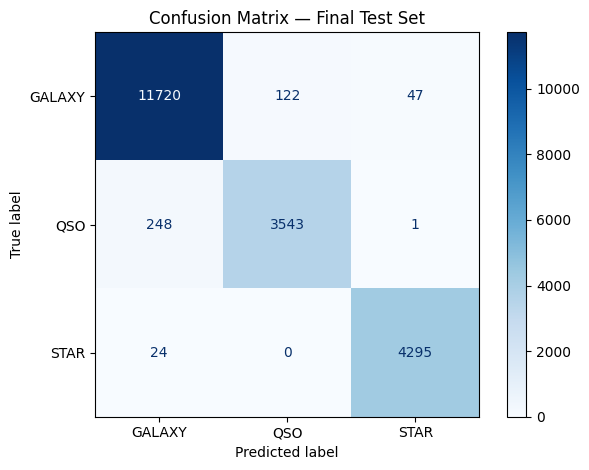

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=sorted(y_train.unique()),
    display_labels=sorted(y_train.unique()), cmap="Blues", values_format="d"
)
plt.title("Confusion Matrix — Final Test Set")
plt.tight_layout()
plt.show()

## 8. Overfitting check

This compares training-fold and validation-fold macro F1-scores for the selected pipeline. A large gap can indicate overfitting; low scores on both sides can indicate underfitting.

This is a diagnostic check, not a new independent estimate: model and feature-count selection have already used cross-validation on the training set. The held-out test result remains the final evaluation.

In [ ]:
overfit_check = cross_validate(final_pipeline, X_train, y_train, cv=cv, scoring="f1_macro",
                               return_train_score=True, n_jobs=1)
mean_train_f1 = overfit_check["train_score"].mean()
mean_validation_f1 = overfit_check["test_score"].mean()
print(f"Mean training-fold F1: {mean_train_f1:.4f}")
print(f"Mean validation F1: {mean_validation_f1:.4f}")
print(f"Train-validation gap: {mean_train_f1 - mean_validation_f1:.4f}")
print(f"Validation F1 standard deviation: {overfit_check['test_score'].std():.4f}")

Mean training-fold F1: 0.9806
Mean validation F1: 0.9732
Train-validation gap: 0.0074
Validation F1 standard deviation: 0.0006


## 9. Results and discussion

Complete this section after running the notebook. Use the actual values from your output.

- **Model comparison:** Which model had the highest cross-validation macro F1? Which model was selected by the speed/performance rule?
- **Baseline:** Did the selected model clearly outperform the Dummy Classifier?
- **Tuning:** Report the before-and-after cross-validation scores.
- **Feature reduction:** How many columns were retained, which features were selected, and how close was the reduced-feature score to the best score?
- **Measurement comparison:** Did removing redshift reduce performance? How did colour-only compare? Remember that colour indices are derived from photometric measurements.
- **Final test performance:** Report test accuracy, macro precision, macro recall and macro F1. Use the confusion matrix to discuss class confusions.
- **Overfitting:** Discuss the training-validation gap and validation-score variation.

### Limitations

ANOVA F-scores assess features individually and may miss interactions. Other methods such as mutual information, recursive feature elimination, sequential selection, model-based selection or permutation importance could give a different subset. The same cross-validation folds are used for model selection, tuning and feature-count selection, so their scores may be optimistic. Nested cross-validation would provide a more rigorous estimate of the selection process. The held-out test set gives the final evaluation for this run.

## 10. Conclusion

After running the notebook, state the selected algorithm and tuned parameters, final test metrics, selected feature names, number of columns removed, and whether the reduced-feature model stayed within the predefined cross-validation tolerance. Also summarise what the measurement comparison suggests, including whether redshift appears useful.

Do not claim that fewer telescope observations are required solely because `SelectKBest` retained fewer columns. That demonstrates feature-column reduction. A claim about reducing actual observations or measurements requires a separate experiment defining which measurements can be omitted and evaluating the resulting data.